In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

DATA_PATH = Path("csv/cybersecurity_dataset.csv")
df = pd.read_csv(DATA_PATH, na_values=["", " "], low_memory=False)

LABEL_ORDER = sorted(df["label"].unique())
df["label"] = pd.Categorical(df["label"], categories=LABEL_ORDER, ordered=True)

In [3]:
print("shape:", df.shape)
print("memory:", df.memory_usage(deep=True).sum() / 1024**2, "MiB")
display(df.dtypes.to_frame("dtype"))
display(df.head(8))

shape: (17600, 53)
memory: 15.151639938354492 MiB


,dtype
label,category
frame.number,int64
frame.time_epoch,float64
frame.time_delta,float64
frame.time_relative,float64
frame.len,int64
frame.cap_len,int64
frame.protocols,str
eth.src,str
eth.dst,str


,label,frame.number,frame.time_epoch,frame.time_delta,frame.time_relative,frame.len,frame.cap_len,frame.protocols,eth.src,eth.dst,...,tcp.options.mss_val,tcp.options.wscale,udp.srcport,udp.dstport,udp.length,udp.stream,icmp.type,icmp.code,icmp.ident,icmp.seq
0,ack,1,1.776857e+09,0.000000,0.000000,54,54,eth:ethertype:ip:tcp,00:00:00:00:00:00,00:00:00:00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ack,2,1.776857e+09,0.000020,0.000020,54,54,eth:ethertype:ip:tcp,00:00:00:00:00:00,00:00:00:00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ack,3,1.776857e+09,0.000007,0.000027,54,54,eth:ethertype:ip:tcp,00:00:00:00:00:00,00:00:00:00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ack,4,1.776857e+09,0.000006,0.000033,54,54,eth:ethertype:ip:tcp,00:00:00:00:00:00,00:00:00:00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ack,5,1.776857e+09,0.000006,0.000039,54,54,eth:ethertype:ip:tcp,00:00:00:00:00:00,00:00:00:00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,ack,6,1.776857e+09,0.000006,0.000045,54,54,eth:ethertype:ip:tcp,00:00:00:00:00:00,00:00:00:00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,ack,7,1.776857e+09,0.000006,0.000051,54,54,eth:ethertype:ip:tcp,00:00:00:00:00:00,00:00:00:00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,ack,8,1.776857e+09,0.000006,0.000057,54,54,eth:ethertype:ip:tcp,00:00:00:00:00:00,00:00:00:00:00:00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


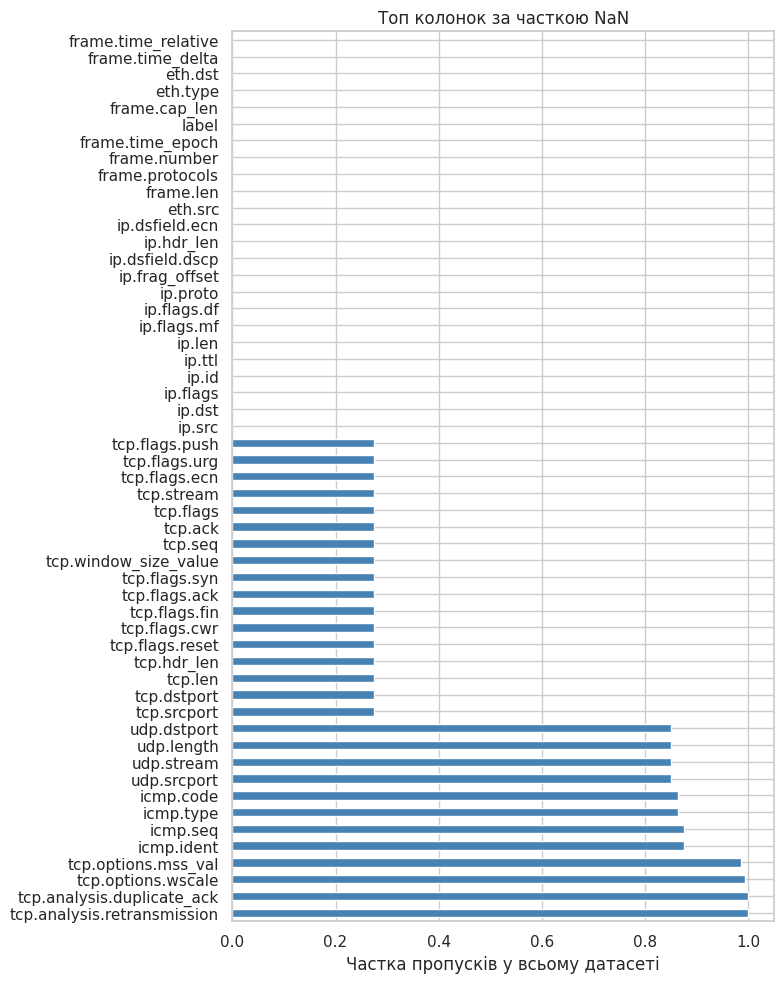

In [4]:
missing = df.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 10))
missing.plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Частка пропусків у всьому датасеті")
ax.set_title("Топ колонок за часткою NaN")
plt.tight_layout()
plt.show()

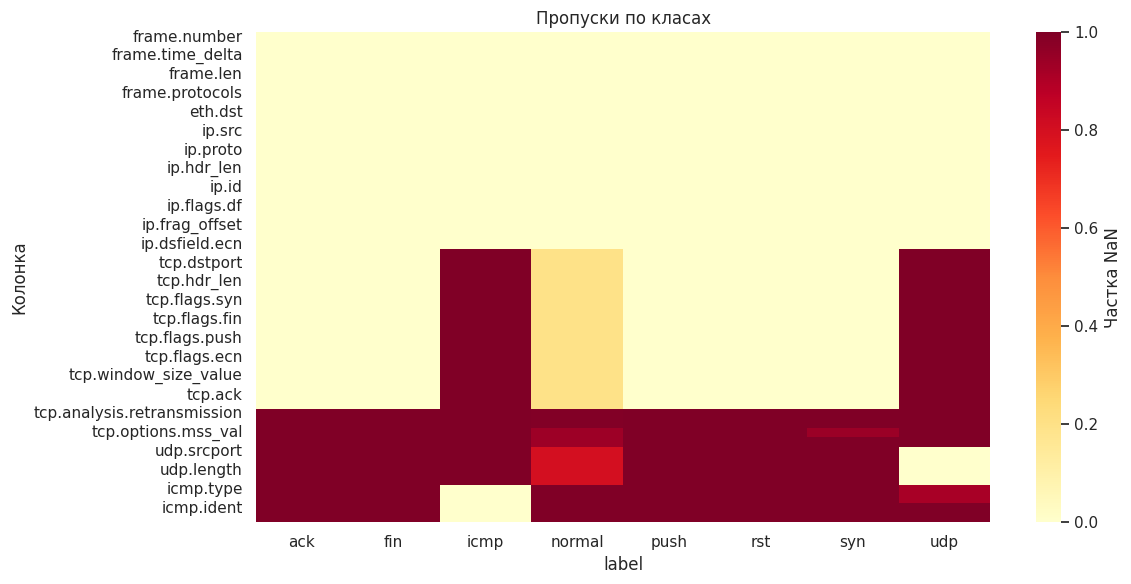

In [5]:
miss_by_label = df.groupby("label", observed=True).apply(lambda g: g.isna().mean(), include_groups=False)
plt.figure(figsize=(12, 6))
sns.heatmap(miss_by_label.T, cmap="YlOrRd", cbar_kws={"label": "Частка NaN"})
plt.title("Пропуски по класах")
plt.ylabel("Колонка")
plt.xlabel("label")
plt.tight_layout()
plt.show()

,count
label,
ack,2200
fin,2200
icmp,2200
normal,2200
push,2200
rst,2200
syn,2200
udp,2200


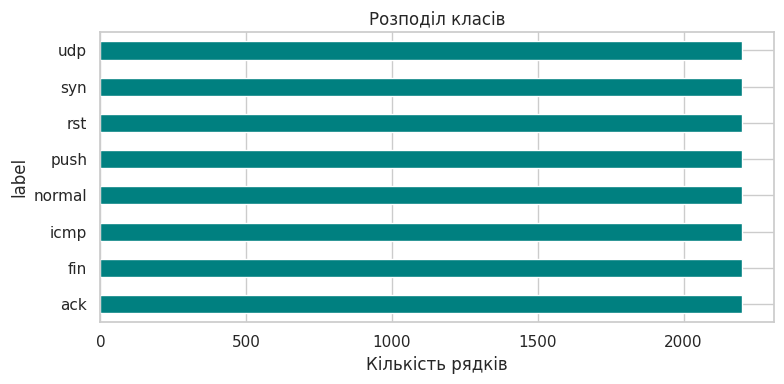

In [6]:
vc = df["label"].value_counts().reindex(LABEL_ORDER)
display(vc.to_frame("count"))
fig, ax = plt.subplots(figsize=(8, 4))
vc.plot(kind="barh", ax=ax, color="teal")
ax.set_xlabel("Кількість рядків")
ax.set_title("Розподіл класів")
plt.tight_layout()
plt.show()

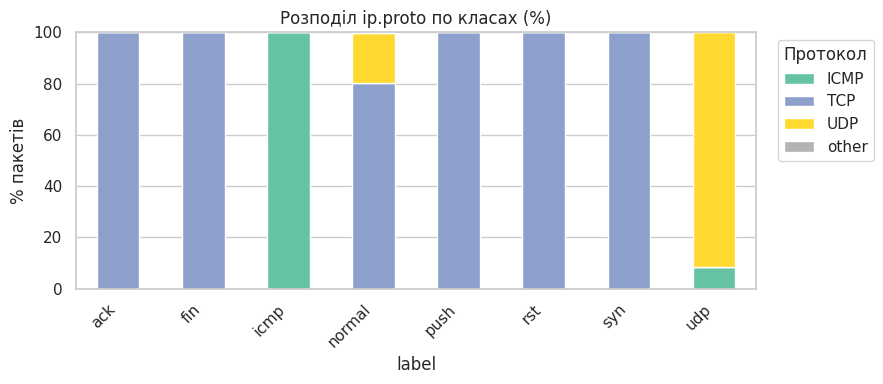

ip_proto_name,ICMP,TCP,UDP,other
label,,,,
ack,0.0,100.00,0.00,0.00
fin,0.0,100.00,0.00,0.00
icmp,100.0,0.00,0.00,0.00
normal,0.0,80.14,19.68,0.18
push,0.0,100.00,0.00,0.00
rst,0.0,100.00,0.00,0.00
syn,0.0,100.00,0.00,0.00
udp,8.5,0.00,91.50,0.00


In [7]:
proto_map = {1: "ICMP", 6: "TCP", 17: "UDP"}
df["ip_proto_name"] = df["ip.proto"].map(proto_map).fillna("other")

proto_ct = (
    df.groupby(["label", "ip_proto_name"], observed=True)
    .size()
    .unstack(fill_value=0)
)
proto_pct = proto_ct.div(proto_ct.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 4))
proto_pct.plot(kind="bar", stacked=True, ax=ax, colormap="Set2")
ax.set_ylabel("% пакетів")
ax.set_xlabel("label")
ax.set_title("Розподіл ip.proto по класах (%)")
ax.legend(title="Протокол", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
display(proto_pct.round(2))

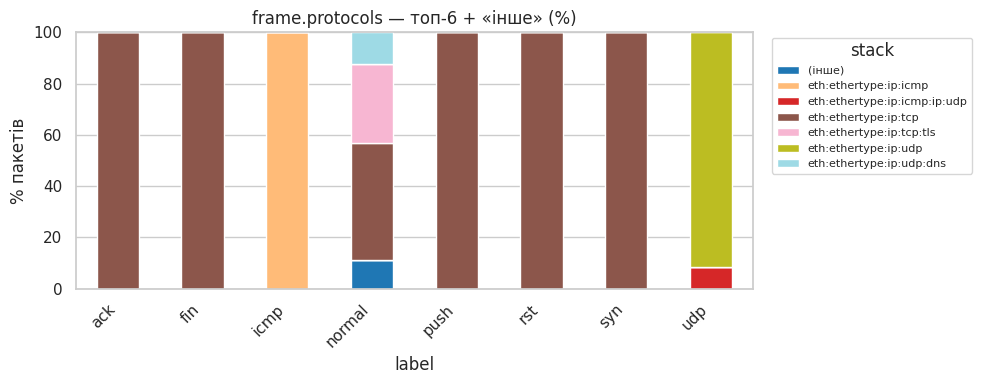

In [16]:
top_n = 6
top_stacks = df["frame.protocols"].value_counts().head(top_n).index.tolist()
tmp = df.assign(
    stack_top=df["frame.protocols"].where(
        df["frame.protocols"].isin(top_stacks), "(інше)"
    )
)
stack_ct = tmp.groupby(["label", "stack_top"], observed=True).size().unstack(fill_value=0)
stack_pct = stack_ct.div(stack_ct.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 4))
stack_pct.plot(kind="bar", stacked=True, ax=ax, colormap="tab20")
ax.set_ylabel("% пакетів")
ax.set_xlabel("label")
ax.set_title(f"frame.protocols — топ-{top_n} + «інше» (%)")
ax.legend(title="stack", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ack,2200.0,54.000,0.000,54.0,54.0,54.0,54.0,54.0
fin,2200.0,54.000,0.000,54.0,54.0,54.0,54.0,54.0
icmp,2200.0,42.000,0.000,42.0,42.0,42.0,42.0,42.0
normal,2200.0,368.912,624.290,42.0,66.0,75.0,398.0,8222.0
push,2200.0,54.000,0.000,54.0,54.0,54.0,54.0,54.0
rst,2200.0,54.000,0.000,54.0,54.0,54.0,54.0,54.0
syn,2200.0,54.227,0.926,54.0,54.0,54.0,54.0,58.0
udp,2200.0,44.380,7.810,42.0,42.0,42.0,42.0,70.0


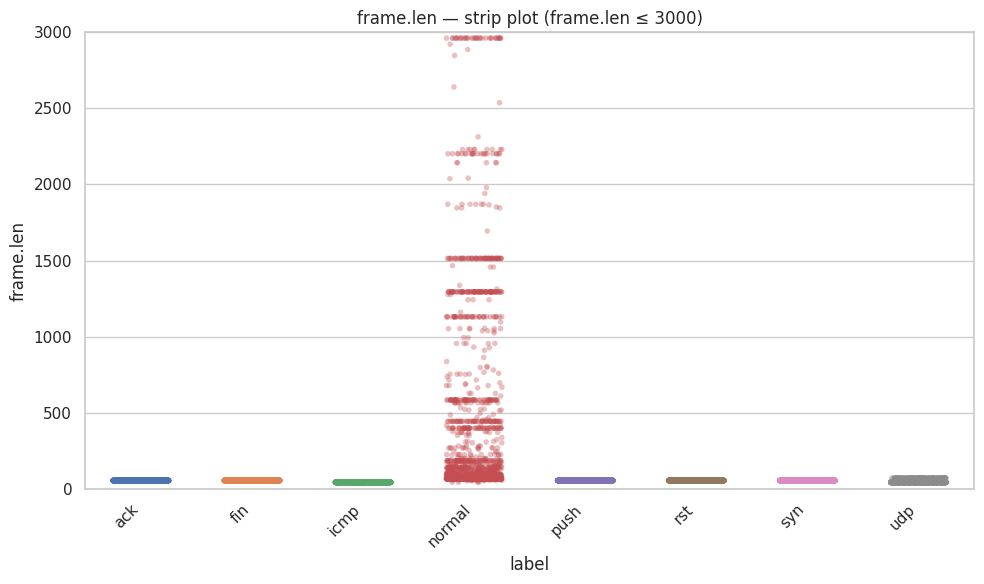

In [9]:
display(df.groupby("label", observed=True)["frame.len"].describe().round(3))

plot_df = df.loc[df["frame.len"] <= 3000]

plt.figure(figsize=(10, 6))
sns.stripplot(
    data=plot_df,
    x="label",
    y="frame.len",
    hue="label",
    legend=False,
    jitter=0.25,
    size=4,
    alpha=0.35,
)
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 3000)
plt.title("frame.len — strip plot (frame.len ≤ 3000)")
plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ack,2200.0,61.108,13.188,1.0,64.0,64.0,64.0,64.0
fin,2200.0,64.000,0.000,64.0,64.0,64.0,64.0,64.0
icmp,2200.0,62.253,10.346,1.0,64.0,64.0,64.0,64.0
normal,2196.0,111.161,80.360,46.0,64.0,64.0,242.0,249.0
push,2200.0,64.000,0.000,64.0,64.0,64.0,64.0,64.0
rst,2200.0,64.000,0.000,64.0,64.0,64.0,64.0,64.0
syn,2200.0,64.000,0.000,64.0,64.0,64.0,64.0,64.0
udp,2200.0,59.705,15.883,1.0,64.0,64.0,64.0,64.0


/tmp/ipykernel_99308/2302845186.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ttl, x="label", y="ip.ttl", palette="flare")


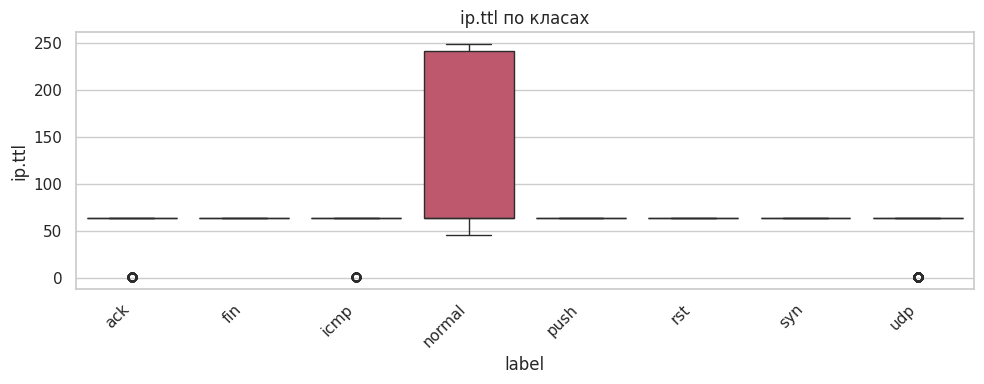

In [10]:
ttl = df.dropna(subset=["ip.ttl"])
display(ttl.groupby("label", observed=True)["ip.ttl"].describe().round(3))

plt.figure(figsize=(10, 4))
sns.boxplot(data=ttl, x="label", y="ip.ttl", palette="flare")
plt.xticks(rotation=45, ha="right")
plt.title("ip.ttl по класах")
plt.tight_layout()
plt.show()

,tcp.flags.syn,tcp.flags.ack,tcp.flags.fin,tcp.flags.reset,tcp.flags.push,tcp.flags.urg
label,,,,,,
ack,0.0000,0.9464,0.0000,0.0536,0.0000,0.0
fin,0.0000,0.0000,1.0000,0.0000,0.0000,0.0
icmp,0.0000,0.0000,0.0000,0.0000,0.0000,0.0
normal,0.0771,0.9609,0.0749,0.0017,0.4203,0.0
push,0.0000,0.0000,0.0000,0.0000,1.0000,0.0
rst,0.0000,0.0000,0.0000,1.0000,0.0000,0.0
syn,0.9936,0.0568,0.0000,0.0064,0.0000,0.0
udp,0.0000,0.0000,0.0000,0.0000,0.0000,0.0


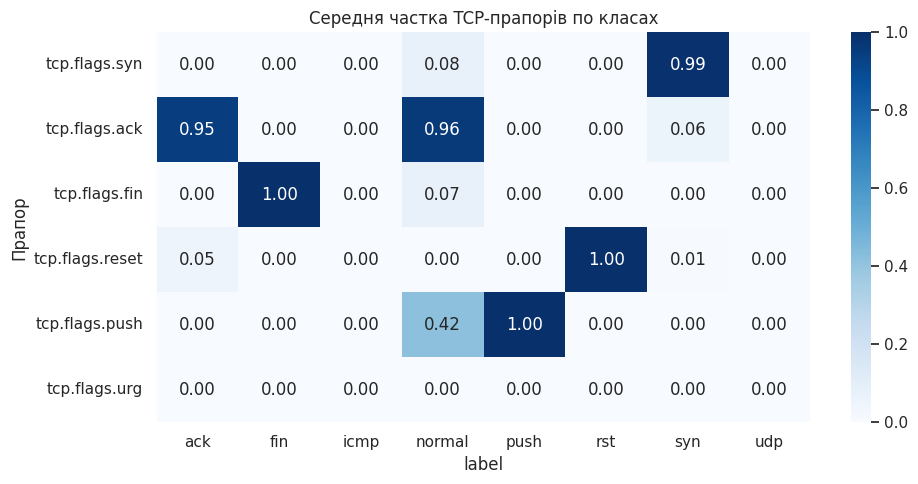

In [11]:
flag_cols = [
    "tcp.flags.syn",
    "tcp.flags.ack",
    "tcp.flags.fin",
    "tcp.flags.reset",
    "tcp.flags.push",
    "tcp.flags.urg",
]
flag_means = df.groupby("label", observed=True)[flag_cols].mean().fillna(0)
display(flag_means.round(4))

plt.figure(figsize=(10, 5))
sns.heatmap(flag_means.T, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Середня частка TCP-прапорів по класах")
plt.ylabel("Прапор")
plt.xlabel("label")
plt.tight_layout()
plt.show()

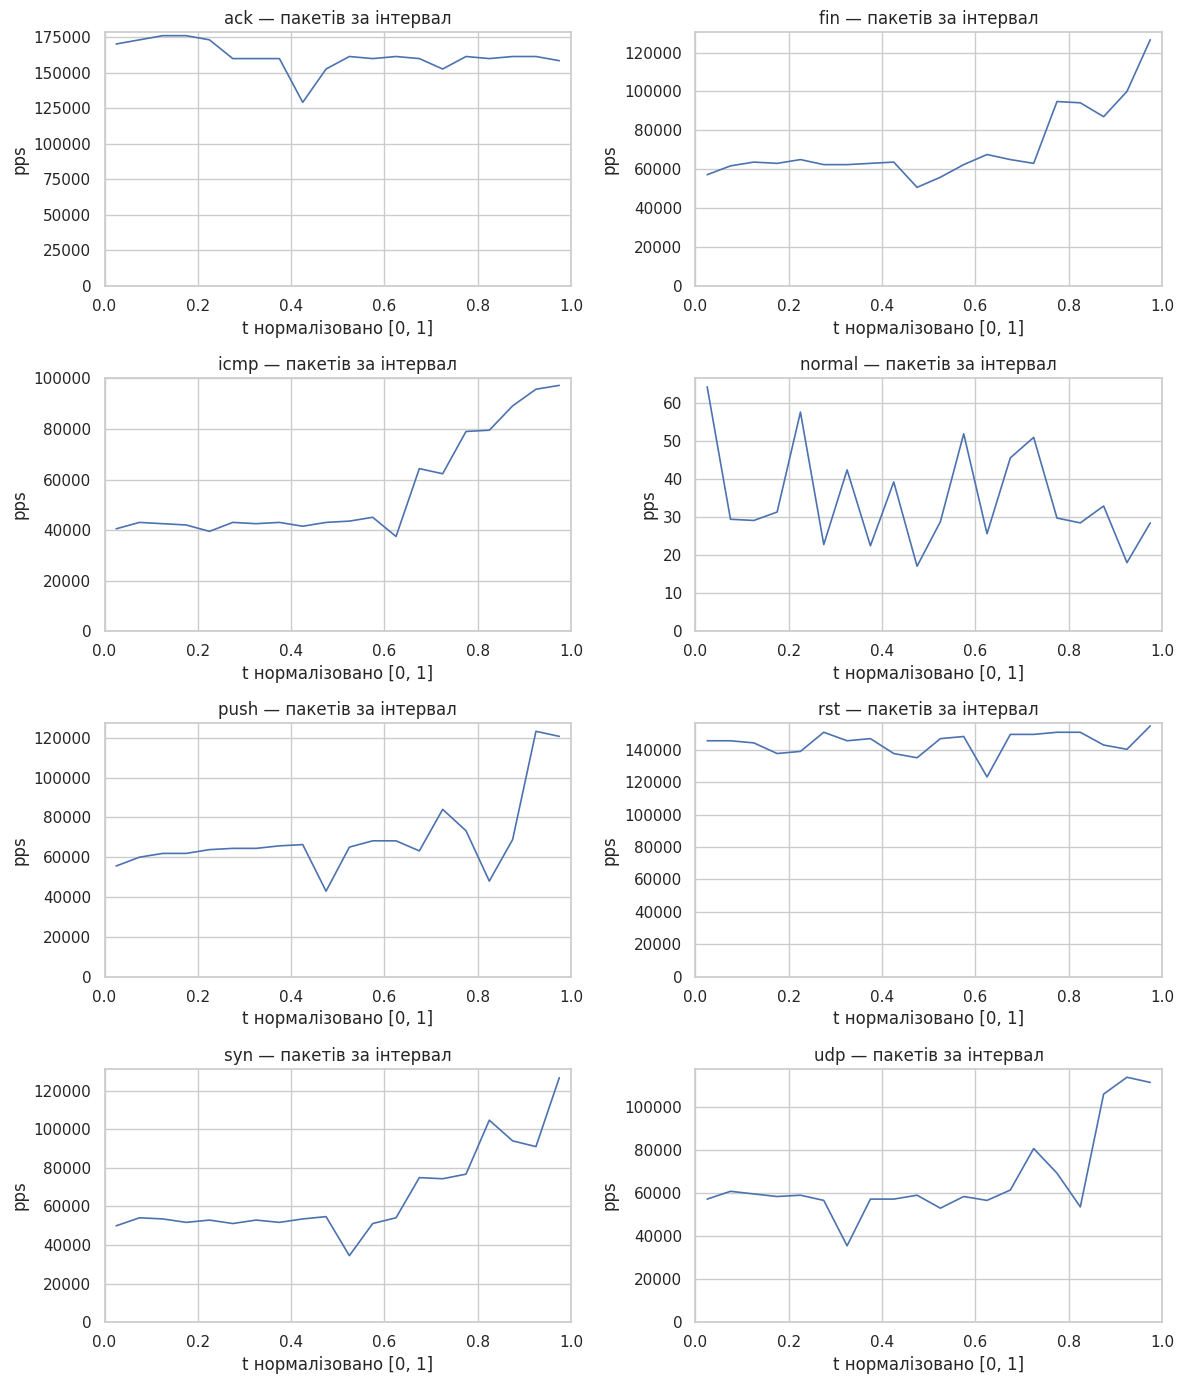

In [12]:
bin_frac = 0.05
n_bins = max(1, int(np.ceil(1 / bin_frac)))
delta_u = 1 / n_bins

fig, axes = plt.subplots(4, 2, figsize=(12, 14), sharey=False)
axes = axes.flatten()

for ax, lab in zip(axes, LABEL_ORDER):
    g = df[df["label"] == lab].copy()
    t0 = g["frame.time_epoch"].min()
    t_rel = g["frame.time_epoch"] - t0
    t_max = float(t_rel.max())
    if t_max > 0:
        u = t_rel / t_max
        edges_u = np.linspace(0, 1, n_bins + 1)
        counts, edges = np.histogram(u, bins=edges_u)
        centers_u = (edges[:-1] + edges[1:]) / 2
        dt = t_max / n_bins
        pps = counts / dt
        ax.plot(centers_u, pps, lw=1.2)
    else:
        ax.annotate(
            "t_max = 0",
            xy=(0.5, 0.5),
            xycoords="axes fraction",
            ha="center",
            fontsize=10,
        )
    ax.set_xlim(0, 1)
    ax.set_ylim(bottom=0)
    ax.set_title(f"{lab} — пакетів за інтервал")
    ax.set_xlabel("t нормалізовано [0, 1]")
    ax.set_ylabel("pps")

plt.tight_layout()
plt.show()

,unique_ip_src,unique_tcp_sport,unique_udp_sport
label,,,
ack,2083,2083,0
fin,2200,2200,0
icmp,2125,0,0
normal,31,94,123
push,2200,2200,0
rst,2200,2200,0
syn,2062,2062,0
udp,2014,0,2013


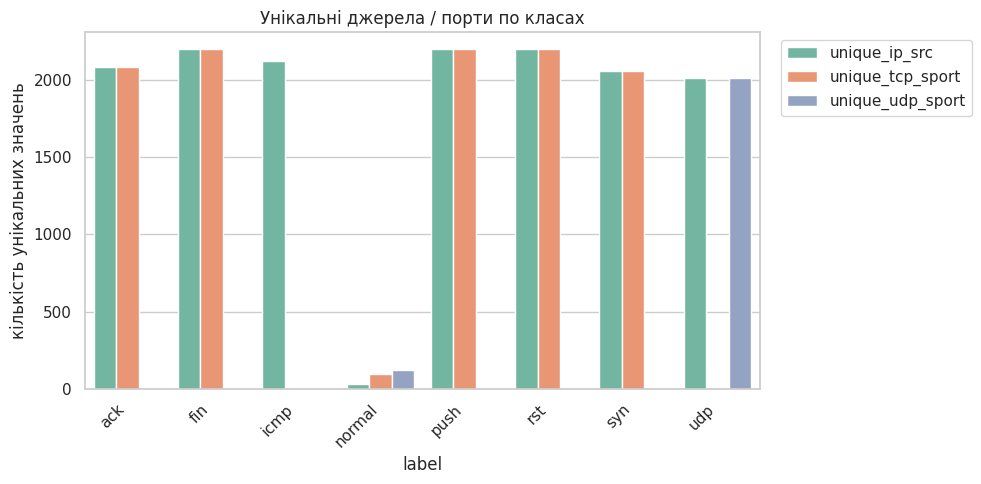

In [13]:
div = df.groupby("label", observed=True).agg(
    unique_ip_src=("ip.src", "nunique"),
    unique_tcp_sport=("tcp.srcport", "nunique"),
    unique_udp_sport=("udp.srcport", "nunique"),
)
display(div)

div_plot = div.reset_index().melt(id_vars="label", var_name="metric", value_name="nunique")
plt.figure(figsize=(10, 5))
sns.barplot(data=div_plot, x="label", y="nunique", hue="metric", palette="Set2")
plt.xticks(rotation=45, ha="right")
plt.title("Унікальні джерела / порти по класах")
plt.ylabel("кількість унікальних значень")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Рядків без ip.id: 4


,count,min,max,mean,std,median,nunique
label,,,,,,,
ack,2200,0.0,65523.0,31333.93,19960.84,30933.0,2059
fin,2200,24.0,65518.0,32273.96,19026.80,31685.5,2171
icmp,2200,3.0,65526.0,33122.61,18967.69,33614.0,2162
normal,2196,0.0,65280.0,26949.89,20381.75,24691.5,1956
push,2200,82.0,65523.0,32854.34,18957.71,32584.0,2164
rst,2200,10.0,65446.0,32685.35,19064.03,33085.0,2170
syn,2200,0.0,65507.0,31860.43,19964.67,32333.0,2026
udp,2200,82.0,65448.0,32444.17,19171.15,31862.5,2170


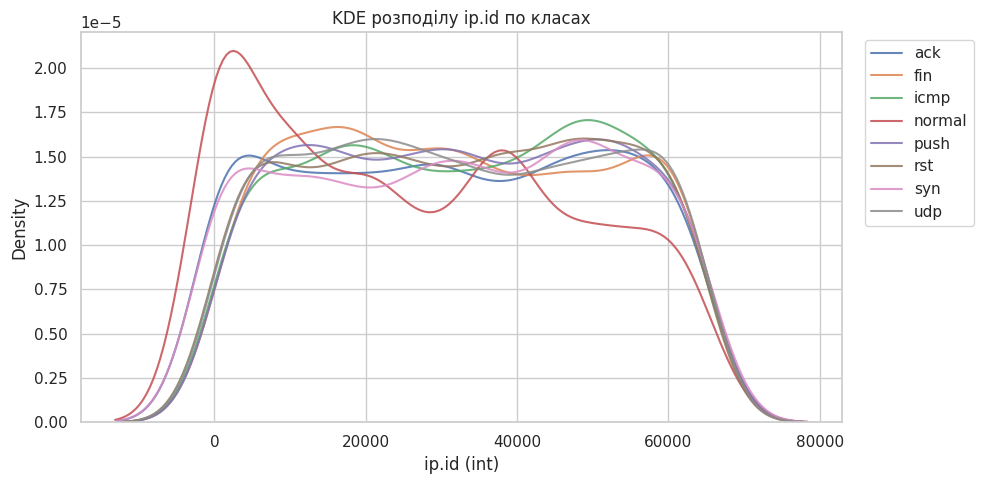

In [14]:
def parse_ip_id(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s.startswith("0x") or s.startswith("0X"):
        return int(s, 16)
    try:
        return int(float(s))
    except ValueError:
        return np.nan


df["ip_id_int"] = df["ip.id"].map(parse_ip_id)
print("Рядків без ip.id:", df["ip_id_int"].isna().sum())
id_stats = df.groupby("label", observed=True)["ip_id_int"].agg(
    ["count", "min", "max", "mean", "std", "median", "nunique"]
).round(2)
display(id_stats)

plt.figure(figsize=(10, 5))
for lab in LABEL_ORDER:
    sub = df.loc[df["label"] == lab, "ip_id_int"].dropna()
    if len(sub) > 1:
        sns.kdeplot(sub, label=lab, common_norm=False, fill=False, alpha=0.85)
plt.xlabel("ip.id (int)")
plt.title("KDE розподілу ip.id по класах")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()